In [20]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip
!unzip -q coco128.zip -d /content/dataset

import os, glob, cv2
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content/dataset/coco128'
print(os.listdir(BASE))

['labels', 'README.txt', 'images', 'LICENSE']


In [21]:
names = ['person','bicycle','car','motorcycle','airplane','bus','train','truck','boat','traffic light','fire hydrant','stop sign','parking meter','bench','bird','cat','dog','horse','sheep','cow','elephant','bear','zebra','giraffe','backpack','umbrella','handbag','tie','suitcase','frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove','skateboard','surfboard','tennis racket','bottle','wine glass','cup','fork','knife','spoon','bowl','banana','apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut','cake','chair','couch','potted plant','bed','dining table','toilet','tv','laptop','mouse','remote','keyboard','cell phone','microwave','oven','toaster','sink','refrigerator','book','clock','vase','scissors','teddy bear','hair drier','toothbrush']

image_paths = sorted(glob.glob(BASE + '/images/*/*.jpg'))
label_paths = sorted(glob.glob(BASE + '/labels/*/*.txt'))
print("Images:", len(image_paths), "| Label files:", len(label_paths))

rows, problems = [], []
for lf in label_paths:
    img_path = lf.replace('/labels/', '/images/').replace('.txt', '.jpg')
    if not os.path.exists(img_path):
        problems.append((os.path.basename(lf), 'label has no image'))
        continue
    for line in open(lf):
        v = line.split()
        if len(v) != 5:
            problems.append((os.path.basename(lf), 'wrong format'))
            continue
        c = int(float(v[0]))
        x, y, w, h = map(float, v[1:])
        rows.append({'image': img_path, 'class_id': c, 'x': x, 'y': y, 'w': w, 'h': h})

ann = pd.DataFrame(rows)
ann['class_name'] = ann['class_id'].apply(lambda i: names[i] if 0 <= i < 80 else 'INVALID')

# corner coordinates of each box (0 to 1)
ann['x1'] = ann['x'] - ann['w'] / 2
ann['x2'] = ann['x'] + ann['w'] / 2
ann['y1'] = ann['y'] - ann['h'] / 2
ann['y2'] = ann['y'] + ann['h'] / 2

print("Total annotated objects:", len(ann))
ann.head()

Images: 128 | Label files: 128
Total annotated objects: 929


,image,class_id,x,y,w,h,class_name,x1,x2,y1,y2
0,/content/dataset/coco128/images/train2017/0000...,45,0.479492,0.688771,0.955609,0.595500,bowl,1.687500e-03,0.957296,0.391021,0.986521
1,/content/dataset/coco128/images/train2017/0000...,45,0.736516,0.247188,0.498875,0.476417,bowl,4.870785e-01,0.985953,0.008980,0.485397
2,/content/dataset/coco128/images/train2017/0000...,50,0.637063,0.732938,0.494125,0.510583,broccoli,3.900005e-01,0.884126,0.477646,0.988229
3,/content/dataset/coco128/images/train2017/0000...,45,0.339438,0.418896,0.678875,0.781500,bowl,5.000000e-07,0.678875,0.028146,0.809646
4,/content/dataset/coco128/images/train2017/0000...,49,0.646836,0.132552,0.118047,0.096937,orange,5.878125e-01,0.705859,0.084083,0.181021


Classes present: 71
class_name
person        254
car            46
cup            36
chair          35
book           29
bowl           28
carrot         24
spoon          22
teddy bear     21
handbag        19
bottle         18
umbrella       18
elephant       17
bird           16
wine glass     16
Name: count, dtype: int64


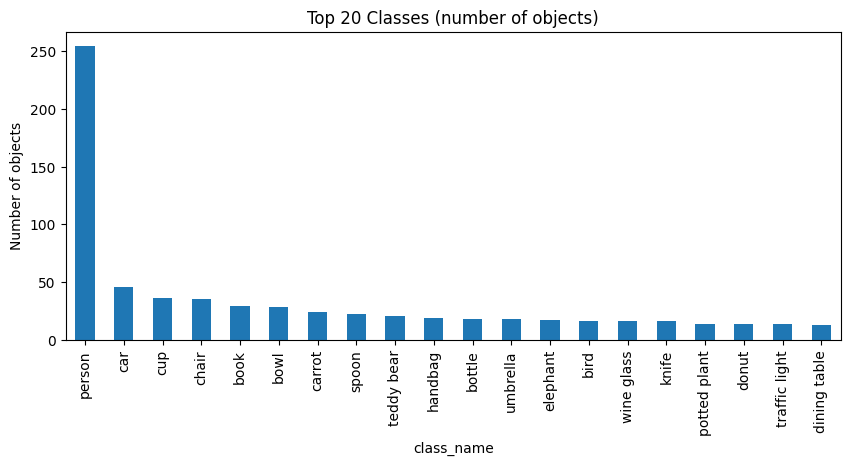

Imbalance ratio (most / least common): 254


In [22]:
obj_counts = ann['class_name'].value_counts()
print("Classes present:", len(obj_counts))
print(obj_counts.head(15))

obj_counts.head(20).plot(kind='bar', figsize=(10, 4), title='Top 20 Classes (number of objects)')
plt.ylabel('Number of objects')
plt.show()

ratio = obj_counts.max() / obj_counts.min()
print(f"Imbalance ratio (most / least common): {ratio:.0f}")

Average objects per image: 7.4
Max objects in one image : 42


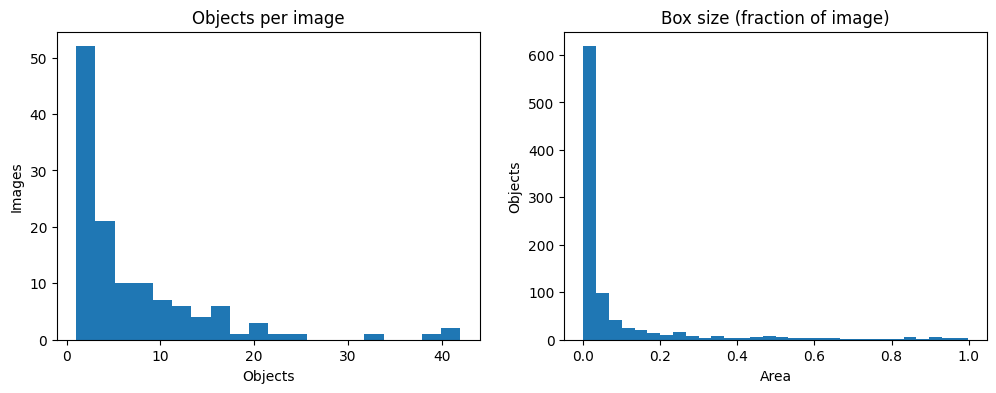

Small objects (< 1% of image): 452


In [23]:
per_image = ann.groupby('image').size()
print("Average objects per image:", round(per_image.mean(), 1))
print("Max objects in one image :", per_image.max())

ann['area'] = ann['w'] * ann['h']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(per_image, bins=20)
plt.title('Objects per image'); plt.xlabel('Objects'); plt.ylabel('Images')

plt.subplot(1, 2, 2)
plt.hist(ann['area'], bins=30)
plt.title('Box size (fraction of image)'); plt.xlabel('Area'); plt.ylabel('Objects')
plt.show()

print("Small objects (< 1% of image):", (ann['area'] < 0.01).sum())

Corrupted images: 0
Average size: 579 x 492
Blurry images (score < 100): 1


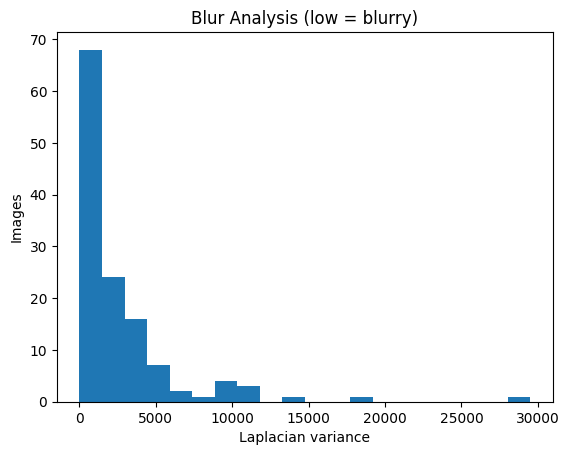

In [24]:
widths, heights, blur, corrupt = [], [], [], []

for p in image_paths:
    img = cv2.imread(p)
    if img is None:
        corrupt.append(p)
        continue
    heights.append(img.shape[0])
    widths.append(img.shape[1])
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur.append(cv2.Laplacian(gray, cv2.CV_64F).var())

print("Corrupted images:", len(corrupt))
print("Average size:", round(sum(widths) / len(widths)), "x", round(sum(heights) / len(heights)))
print("Blurry images (score < 100):", sum(b < 100 for b in blur))

plt.hist(blur, bins=20)
plt.title('Blur Analysis (low = blurry)')
plt.xlabel('Laplacian variance'); plt.ylabel('Images')
plt.show()

In [25]:
imgs_without_label = [os.path.basename(p) for p in image_paths
                      if not os.path.exists(p.replace('/images/', '/labels/').replace('.jpg', '.txt'))]

bad_class = ann[(ann['class_id'] < 0) | (ann['class_id'] > 79)]
bad_range = ann[(ann['x'] < 0) | (ann['x'] > 1) | (ann['y'] < 0) | (ann['y'] > 1) |
                (ann['w'] <= 0) | (ann['w'] > 1) | (ann['h'] <= 0) | (ann['h'] > 1)]
outside = ann[(ann['x1'] < -0.001) | (ann['y1'] < -0.001) | (ann['x2'] > 1.001) | (ann['y2'] > 1.001)]
dups = ann[ann.duplicated(['image', 'class_id', 'x', 'y', 'w', 'h'], keep=False)]

print("Images with no label file   :", len(imgs_without_label), imgs_without_label)
print("Label files with no image   :", len(problems), [p[0] for p in problems])
print("Invalid class IDs           :", len(bad_class))
print("Values outside 0-1 / size<=0:", len(bad_range))
print("Boxes outside the image     :", len(outside))
print("Duplicate boxes             :", len(dups))

Images with no label file   : 2 ['000000000250.jpg', '000000000508.jpg']
Label files with no image   : 2 ['000000000656.txt', '000000000659.txt']
Invalid class IDs           : 0
Values outside 0-1 / size<=0: 0
Boxes outside the image     : 0
Duplicate boxes             : 0


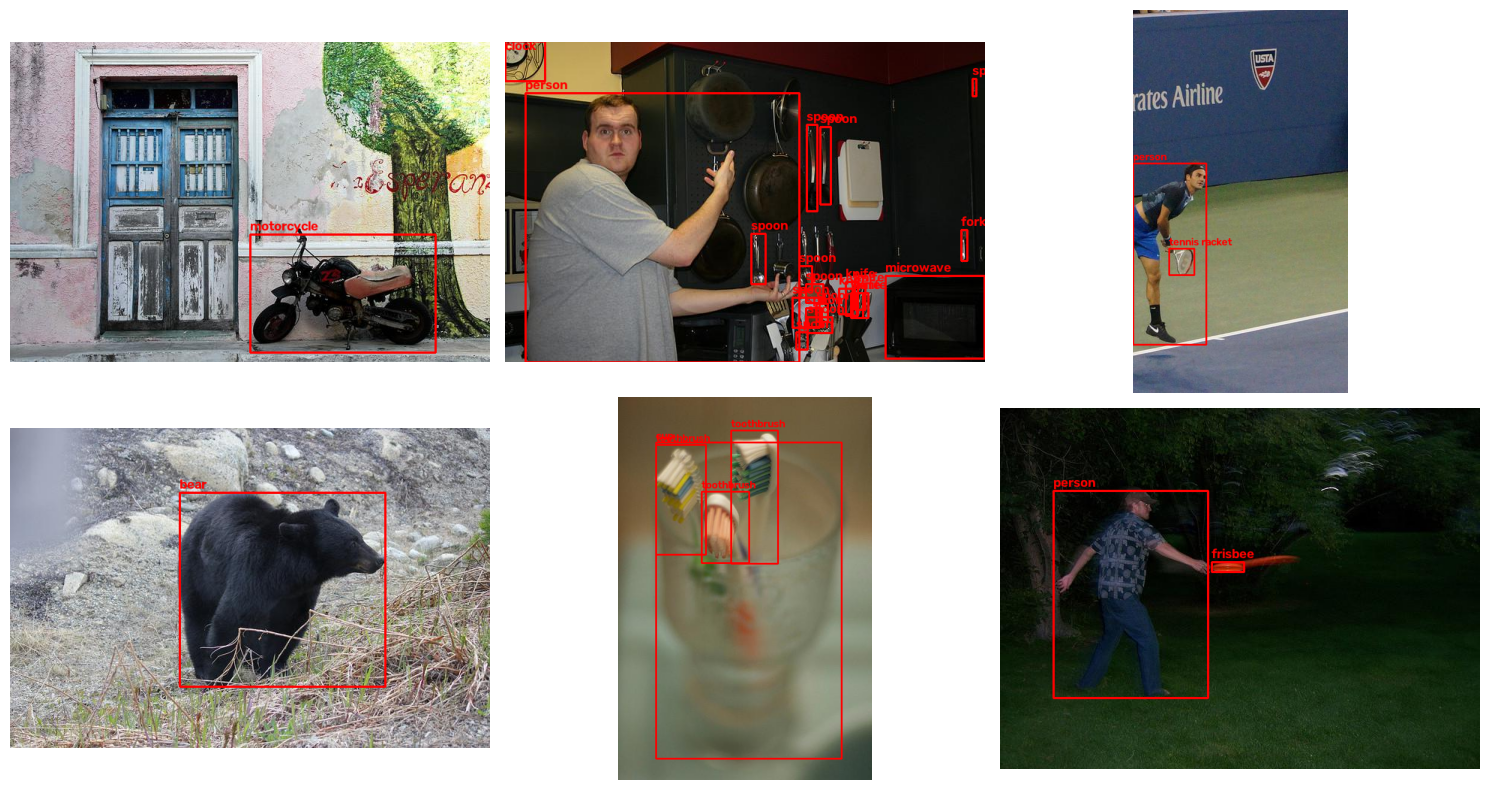

In [26]:
sample = ann['image'].drop_duplicates().sample(6, random_state=1)

plt.figure(figsize=(15, 8))
for i, p in enumerate(sample):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for _, r in ann[ann['image'] == p].iterrows():
        x1, y1, x2, y2 = int(r.x1 * W), int(r.y1 * H), int(r.x2 * W), int(r.y2 * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, r.class_name, (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    plt.subplot(2, 3, i + 1)
    plt.imshow(img); plt.axis('off')
plt.tight_layout()
plt.show()

In [27]:
print("========== DATASET AUDIT REPORT ==========")
print("Total images             :", len(image_paths))
print("Total annotated objects  :", len(ann))
print("Classes present          :", ann['class_name'].nunique(), "of 80")
print("Most common class        :", obj_counts.index[0], "-", obj_counts.iloc[0])
print("Avg objects per image    :", round(per_image.mean(), 1))
print("Corrupted images         :", len(corrupt))
print("Blurry images            :", sum(b < 100 for b in blur))
print("Images without labels    :", len(imgs_without_label))
print("Labels without images    :", len(problems))
print("Invalid annotations      :", len(bad_class) + len(bad_range) + len(outside))
print("Duplicate boxes          :", len(dups))
print("==========================================")

========== DATASET AUDIT REPORT ==========
Total images             : 128
Total annotated objects  : 929
Classes present          : 71 of 80
Most common class        : person - 254
Avg objects per image    : 7.4
Corrupted images         : 0
Blurry images            : 1
Images without labels    : 2
Labels without images    : 2
Invalid annotations      : 0
Duplicate boxes          : 0
